# 09 — Avaliação da distribuição prevista com PIT e CRPS

O PIT e o CRPS avaliam a distribuição prevista nos mesmos 2.717 pregões
de teste usados para VaR e ES.

O PIT é a probabilidade acumulada atribuída ao retorno observado,
`u = F(y)` (Diebold; Gunther; Tay, 1998). Sob uma distribuição condicional
corretamente especificada, os valores devem ser uniformes entre 0 e 1 e
não apresentar dependência temporal. Um histograma em U pode indicar
dispersão insuficiente; concentração no centro pode indicar dispersão
excessiva. Assimetrias podem sugerir viés. Esses formatos são diagnósticos,
sem identificar isoladamente a causa do desajuste.

A curva acumulada é comparada à diagonal da uniforme pelo teste de
Kolmogorov–Smirnov. O teste de Berkowitz (2001) transforma o PIT em normal
e examina conjuntamente média zero, variância unitária e ausência de autocorrelação.

O CRPS mede a distância entre a distribuição prevista e o valor observado,
na unidade do retorno (Gneiting; Raftery, 2007). Valores menores indicam
melhor desempenho. As diferenças diárias são comparadas por Diebold–Mariano.

Os cenários são reconstruídos com as mesmas regras do VaR/ES e conferidos
contra as previsões salvas por `src/risk/scenarios.py`. O cálculo está em
`scripts/evaluate_density.py`.

In [1]:
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

PROJECT_ROOT = Path.cwd() if (Path.cwd() / "config.yaml").exists() else Path.cwd().parent
DENSITY_DIR = PROJECT_ROOT / "reports" / "tables" / "walk_forward" / "density"
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .25, "grid.color": "#c8c8c8",
                     "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#8a8a8a",
                     "xtick.color": "#555", "ytick.color": "#555", "axes.labelcolor": "#333",
                     "axes.titlecolor": "#222", "legend.frameon": False})

# Paleta dos modelos; a referência FHS-EWMA usa cinza e linha tracejada.
MODELS = {"hmm_lstm": ("HMM-LSTM", "#2a78d6", "-"), "lstm": ("LSTM", "#1baf7a", "-"),
          "ms_garch": ("MS-GARCH", "#eb6834", "-"), "zero_mean_reference": ("FHS-EWMA", "#6f6f6f", "--")}
ORDER = ["hmm_lstm", "lstm", "ms_garch", "zero_mean_reference"]

if not (DENSITY_DIR / "pit_crps.parquet").exists():
    subprocess.run([sys.executable, str(PROJECT_ROOT / "scripts" / "evaluate_density.py")], check=True)
daily = pd.read_parquet(DENSITY_DIR / "pit_crps.parquet")
summary = pd.read_csv(DENSITY_DIR / "resumo.csv")
dm = pd.read_csv(DENSITY_DIR / "crps_dm.csv")
n_days = daily.target.nunique()
print(f"{n_days} dias de teste, {daily.estresse.groupby(daily.target).first().sum()} em estresse")

2717 dias de teste, 289 em estresse


## PIT: histogramas

A faixa cinza é o intervalo de 95% esperado para cada barra se o PIT fosse uniforme.

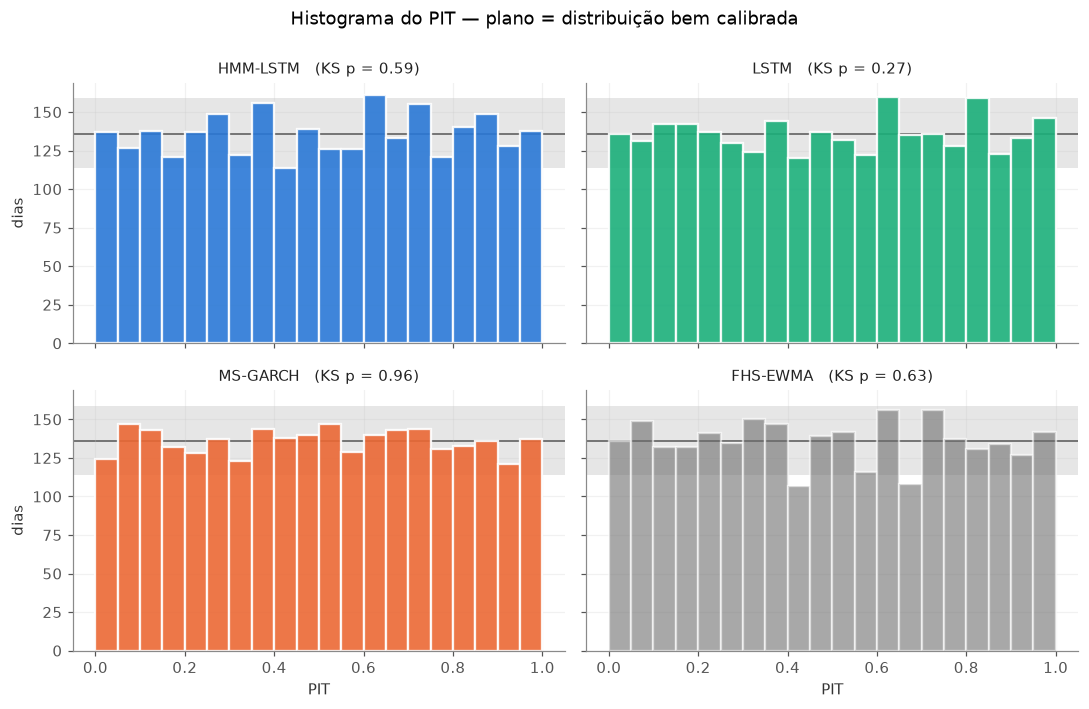

In [2]:
bins = 20
expected = n_days / bins
band = stats.binom.ppf([.025, .975], n_days, 1 / bins)
fig, axes = plt.subplots(2, 2, figsize=(10, 6.4), sharex=True, sharey=True)
for ax, model in zip(axes.flat, ORDER):
    name, color, _ = MODELS[model]
    u = daily.loc[daily.model == model, "pit"]
    ax.axhspan(band[0], band[1], color="#e6e6e6", lw=0, zorder=0)
    ax.axhline(expected, color="#555", lw=1, zorder=1)
    ax.hist(u, bins=bins, range=(0, 1), color=color, edgecolor="white", linewidth=1.5, zorder=2,
            alpha=.9 if model != "zero_mean_reference" else .6)
    row = summary.query("segmento == 'todos' and modelo == @model").iloc[0]
    ax.set_title(f"{name}   (KS p = {row.ks_p:.2f})", fontsize=10)
for ax in axes[1]:
    ax.set_xlabel("PIT")
for ax in axes[:, 0]:
    ax.set_ylabel("dias")
fig.suptitle("Histograma do PIT — plano = distribuição bem calibrada", y=1.0)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "09_pit_histogramas.png", bbox_inches="tight")

## Curva acumulada do PIT

O painel esquerdo compara a distribuição empírica à uniforme. O direito amplia
o desvio em relação à diagonal. A faixa cinza corresponde ao limite do teste KS a 5%.

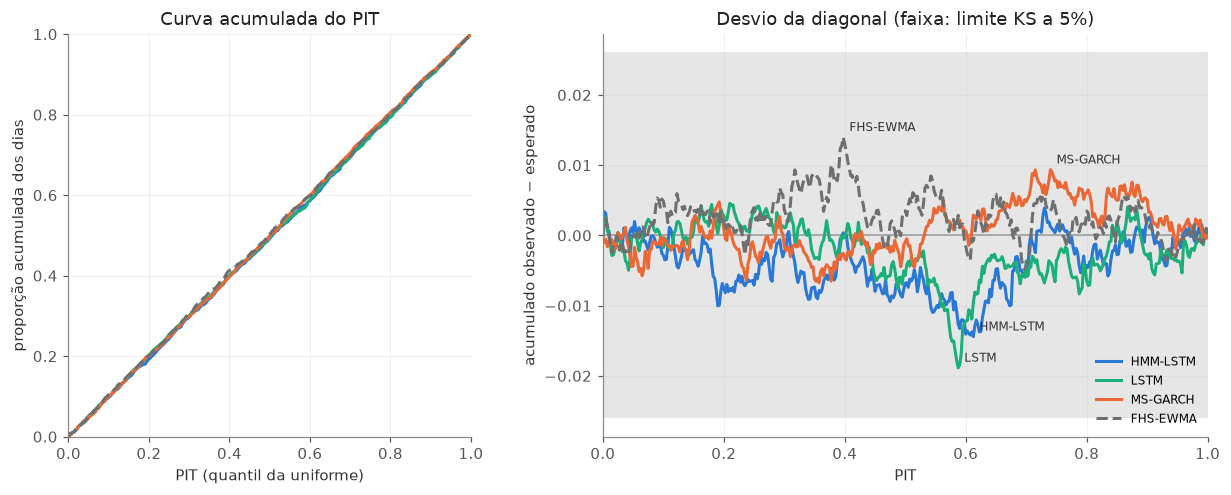

In [3]:
grid = np.linspace(0, 1, 401)
ks_crit = 1.358 / np.sqrt(n_days)
fig, (left, right) = plt.subplots(1, 2, figsize=(11.5, 4.6), gridspec_kw={"width_ratios": [1, 1.35]})
left.plot([0, 1], [0, 1], color="#999", lw=1)
right.axhspan(-ks_crit, ks_crit, color="#e6e6e6", lw=0)
right.axhline(0, color="#999", lw=1)
for model in ORDER:
    name, color, style = MODELS[model]
    u = np.sort(daily.loc[daily.model == model, "pit"].to_numpy())
    ecdf = np.searchsorted(u, grid, side="right") / len(u)
    left.plot(grid, ecdf, color=color, ls=style, lw=2, label=name)
    right.plot(grid, ecdf - grid, color=color, ls=style, lw=2, label=name)
    peak = np.argmax(np.abs(ecdf - grid))
    right.annotate(name, (grid[peak], (ecdf - grid)[peak]), xytext=(4, 4), textcoords="offset points",
                   fontsize=8, color="#333")
left.set(xlabel="PIT (quantil da uniforme)", ylabel="proporção acumulada dos dias",
         title="Curva acumulada do PIT", xlim=(0, 1), ylim=(0, 1))
left.set_aspect("equal")
right.set(xlabel="PIT", ylabel="acumulado observado − esperado",
          title="Desvio da diagonal (faixa: limite KS a 5%)", xlim=(0, 1))
right.legend(loc="lower right", fontsize=8)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "09_pit_curva_acumulada.png", bbox_inches="tight")

In [4]:
names = {m: v[0] for m, v in MODELS.items()}
table = summary.assign(modelo=summary.modelo.map(names)).set_index(["segmento", "modelo"])
table = table[["n", "crps_medio", "ks", "ks_p", "berkowitz_p", "berkowitz_mu", "berkowitz_sigma",
               "berkowitz_rho", "berkowitz_n_pairs", "berkowitz_gap_pairs_excluded", "pit_abaixo_5%", "pit_acima_95%"]]
table["crps_medio"] *= 100
table = table.rename(columns={"crps_medio": "CRPS médio (%)", "ks": "KS", "ks_p": "KS p",
                              "berkowitz_p": "Berkowitz p", "berkowitz_mu": "μ", "berkowitz_sigma": "σ",
                              "berkowitz_rho": "ρ", "pit_abaixo_5%": "PIT < 0,05", "pit_acima_95%": "PIT > 0,95"})
table.reindex(pd.MultiIndex.from_product([["todos", "estresse", "demais_regimes"],
                                          [names[m] for m in ORDER]])).round(4)

n  CRPS médio (%)      KS    KS p  Berkowitz p  \
todos          HMM-LSTM  2717          0.6413  0.0148  0.5863       0.7351   
               LSTM      2717          0.6333  0.0191  0.2693       0.1316   
               MS-GARCH  2717          0.6227  0.0096  0.9624       0.0001   
               FHS-EWMA  2717          0.6264  0.0143  0.6318       0.0000   
estresse       HMM-LSTM   289          0.9364  0.1187  0.0005       0.0003   
               LSTM       289          0.9227  0.1001  0.0057       0.0042   
               MS-GARCH   289          0.9105  0.0719  0.0963       0.0037   
               FHS-EWMA   289          0.9162  0.0860  0.0262       0.0003   
demais_regimes HMM-LSTM  2428          0.6062  0.0287  0.0355       0.2954   
               LSTM      2428          0.5988  0.0277  0.0472       0.1974   
               MS-GARCH  2428          0.5884  0.0136  0.7559       0.0013   
               FHS-EWMA  2428          0.5920  0.0135  0.7641       0.0018   

                              μ       σ       ρ  berkowitz_n_pairs  \
todos          HMM-LSTM  0.0109  1.0037 -0.0181               2694   
               LSTM      0.0061  1.0089 -0.0431               2694   
               MS-GARCH -0.0036  0.9842 -0.0896               2694   
               FHS-EWMA -0.0101  0.9988 -0.0944               2694   
estresse       HMM-LSTM -0.2241  0.9583 -0.1160                280   
               LSTM     -0.1621  0.9482 -0.1244                280   
               MS-GARCH -0.1189  1.0253 -0.1682                280   
               FHS-EWMA -0.1319  0.9323 -0.2005                280   
demais_regimes HMM-LSTM  0.0384  1.0037 -0.0065               2401   
               LSTM      0.0255  1.0128 -0.0310               2401   
               MS-GARCH  0.0091  0.9773 -0.0757               2401   
               FHS-EWMA  0.0037  1.0041 -0.0788               2401   

                         berkowitz_gap_pairs_excluded  PIT < 0,05  PIT > 0,95  
todos          HMM-LSTM                            22      0.0504      0.0508  
               LSTM                                22      0.0501      0.0537  
               MS-GARCH                            22      0.0456      0.0504  
               FHS-EWMA                            22      0.0501      0.0523  
estresse       HMM-LSTM                             8      0.0796      0.0242  
               LSTM                                 8      0.0727      0.0311  
               MS-GARCH                             8      0.0657      0.0554  
               FHS-EWMA                             8      0.0588      0.0381  
demais_regimes HMM-LSTM                            26      0.0470      0.0540  
               LSTM                                26      0.0474      0.0564  
               MS-GARCH                            26      0.0432      0.0498  
               FHS-EWMA                            26      0.0490      0.0540

No Berkowitz, μ e σ medem a calibração (o ideal é 0 e 1) e ρ, a autocorrelação dos PITs (o
ideal é 0). As colunas "PIT < 0,05" e "PIT > 0,95" mostram com que frequência o retorno caiu
nas caudas de 5% previstas, o equivalente a uma violação do VaR de 95% de cada lado.

## CRPS: modelo × MS-GARCH, dia a dia

Cada ponto é um dia. Acima da diagonal, o modelo errou mais que o MS-GARCH naquele dia.

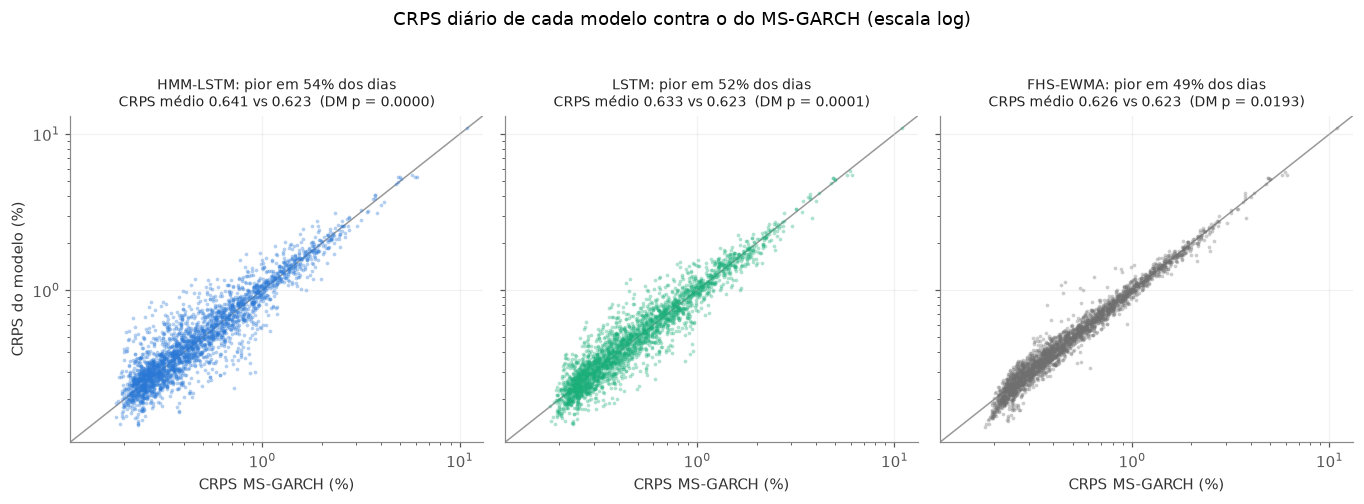

In [5]:
crps = daily.pivot(index="target", columns="model", values="crps") * 100
fig, axes = plt.subplots(1, 3, figsize=(12.5, 4.4), sharex=True, sharey=True)
low, high = crps.min().min() * .8, crps.max().max() * 1.2
for ax, model in zip(axes, ["hmm_lstm", "lstm", "zero_mean_reference"]):
    name, color, _ = MODELS[model]
    ax.plot([low, high], [low, high], color="#999", lw=1, zorder=1)
    ax.scatter(crps["ms_garch"], crps[model], s=6, color=color, alpha=.35, lw=0, zorder=2)
    worse = (crps[model] > crps["ms_garch"]).mean()
    row = dm.query("segmento == 'todos' and a == @model and b == 'ms_garch'").iloc[0]
    ax.set_title(f"{name}: pior em {worse:.0%} dos dias\nCRPS médio {row.crps_a*100:.3f} vs {row.crps_b*100:.3f}  "
                 f"(DM p = {row.dm_p:.4f})", fontsize=9)
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlim(low, high); ax.set_ylim(low, high)
    ax.set_xlabel("CRPS MS-GARCH (%)")
axes[0].set_ylabel("CRPS do modelo (%)")
fig.suptitle("CRPS diário de cada modelo contra o do MS-GARCH (escala log)", y=1.03)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "09_crps_vs_msgarch.png", bbox_inches="tight")

Os CRPS diários apresentam grande dispersão em torno da diagonal, pois todos
os modelos são avaliados sobre o mesmo retorno observado. A soma das diferenças
permite examinar como a vantagem relativa evolui durante o teste.

## Diferença acumulada de CRPS em relação ao MS-GARCH

Uma linha crescente indica acúmulo de CRPS maior que o do MS-GARCH. As faixas
sombreadas marcam os dias de estresse identificados pelo HMM.

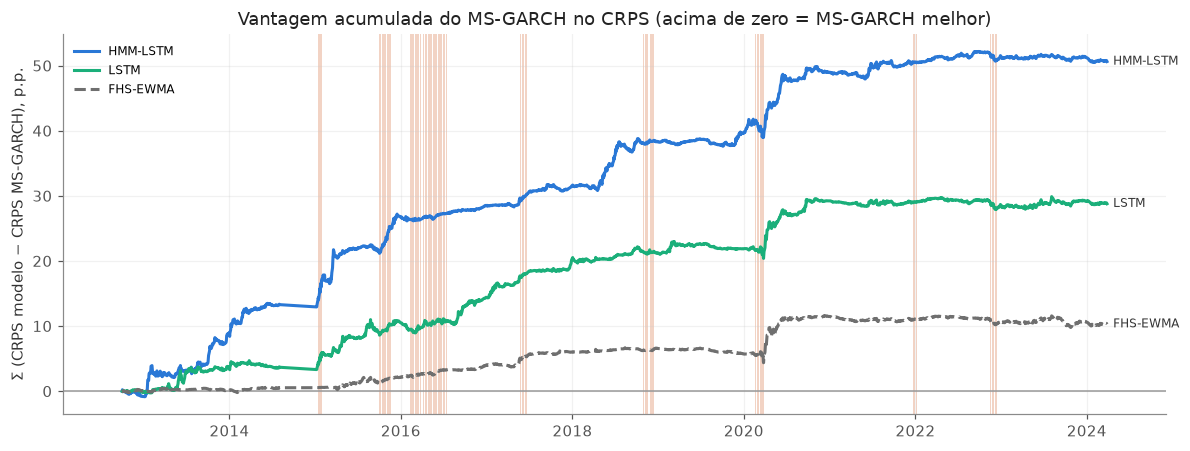

In [6]:
stress = daily.drop_duplicates("target").set_index("target").estresse.sort_index()
fig, ax = plt.subplots(figsize=(11, 4.2))
for date in stress[stress].index:
    ax.axvspan(date, date + pd.Timedelta(days=1), color="#f2d3c4", lw=0, zorder=0)
ax.axhline(0, color="#999", lw=1)
for model in ["hmm_lstm", "lstm", "zero_mean_reference"]:
    name, color, style = MODELS[model]
    path = (crps[model] - crps["ms_garch"]).sort_index().cumsum()
    ax.plot(path.index, path, color=color, ls=style, lw=2, label=name)
    ax.annotate(name, (path.index[-1], path.iloc[-1]), xytext=(4, 0), textcoords="offset points",
                va="center", fontsize=8, color="#333")
ax.set_ylabel("Σ (CRPS modelo − CRPS MS-GARCH), p.p.")
ax.set_title("Vantagem acumulada do MS-GARCH no CRPS (acima de zero = MS-GARCH melhor)")
ax.legend(loc="upper left", fontsize=8)
ax.margins(x=.06)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "09_crps_acumulado.png", bbox_inches="tight")

In [7]:
d = dm.assign(a=dm.a.map(names), b=dm.b.map(names))
d["par"] = d.a + " vs " + d.b
d["melhor (p<0,05)"] = np.where(d.dm_p < .05, np.where(d.diferenca_a_menos_b > 0, d.b, d.a), "—")
d["CRPS a (%)"], d["CRPS b (%)"] = d.crps_a * 100, d.crps_b * 100
d.set_index(["segmento", "par"])[["CRPS a (%)", "CRPS b (%)", "dm", "dm_p", "melhor (p<0,05)"]].round(4)

CRPS a (%)  CRPS b (%)      dm    dm_p  \
segmento       par                                                            
todos          HMM-LSTM vs MS-GARCH      0.6413      0.6227  5.3348  0.0000   
               LSTM vs MS-GARCH          0.6333      0.6227  3.9929  0.0001   
               FHS-EWMA vs MS-GARCH      0.6264      0.6227  2.3400  0.0193   
               HMM-LSTM vs LSTM          0.6413      0.6333  2.7078  0.0068   
               HMM-LSTM vs FHS-EWMA      0.6413      0.6264  4.7143  0.0000   
estresse       HMM-LSTM vs MS-GARCH      0.9364      0.9105  2.0341  0.0419   
               LSTM vs MS-GARCH          0.9227      0.9105  1.2165  0.2238   
               FHS-EWMA vs MS-GARCH      0.9162      0.9105  0.9347  0.3499   
               HMM-LSTM vs LSTM          0.9364      0.9227  1.6293  0.1032   
               HMM-LSTM vs FHS-EWMA      0.9364      0.9162  1.8671  0.0619   
demais_regimes HMM-LSTM vs MS-GARCH      0.6062      0.5884  4.9953  0.0000   
               LSTM vs MS-GARCH          0.5988      0.5884  3.9066  0.0001   
               FHS-EWMA vs MS-GARCH      0.5920      0.5884  2.2641  0.0236   
               HMM-LSTM vs LSTM          0.6062      0.5988  2.3306  0.0198   
               HMM-LSTM vs FHS-EWMA      0.6062      0.5920  4.3494  0.0000   

                                    melhor (p<0,05)  
segmento       par                                   
todos          HMM-LSTM vs MS-GARCH        MS-GARCH  
               LSTM vs MS-GARCH            MS-GARCH  
               FHS-EWMA vs MS-GARCH        MS-GARCH  
               HMM-LSTM vs LSTM                LSTM  
               HMM-LSTM vs FHS-EWMA        FHS-EWMA  
estresse       HMM-LSTM vs MS-GARCH        MS-GARCH  
               LSTM vs MS-GARCH                   —  
               FHS-EWMA vs MS-GARCH               —  
               HMM-LSTM vs LSTM                   —  
               HMM-LSTM vs FHS-EWMA               —  
demais_regimes HMM-LSTM vs MS-GARCH        MS-GARCH  
               LSTM vs MS-GARCH            MS-GARCH  
               FHS-EWMA vs MS-GARCH        MS-GARCH  
               HMM-LSTM vs LSTM                LSTM  
               HMM-LSTM vs FHS-EWMA        FHS-EWMA

## Discussão do PIT e do CRPS

No total, o KS não rejeita a uniformidade dos quatro modelos. O MS-GARCH tem
a menor distância à diagonal: KS = 0,010, com p = 0,96, contra distâncias
de 0,014 a 0,019 nos demais. Nos demais regimes, o teste rejeita as redes
(p próximo de 0,04 e 0,05), mas não o MS-GARCH e a FHS-EWMA.

No estresse, os retornos ficam abaixo do previsto com maior frequência.
A HMM-LSTM apresenta 8,0% dos dias abaixo do quantil previsto de 5%
e 2,4% acima do de 95%, em linha com o deslocamento observado no notebook 05.
Somente o MS-GARCH não é rejeitado pelo KS nesse segmento (p = 0,10).

O teste de Berkowitz rejeita o MS-GARCH e a FHS-EWMA no total. Embora média
e desvio transformados fiquem próximos de 0 e 1, a autocorrelação do PIT
é cerca de −0,09. Nas redes, fica próxima de −0,02 e −0,04. Isso sugere
que a previsão da média captura parte da dependência, mas não elimina
as demais limitações de desempenho. O teste usa somente pares de sessões adjacentes do calendário, inclusive nos
segmentos. O número de pares e as exclusões são registrados na avaliação.

O CRPS médio segue a ordem MS-GARCH, FHS-EWMA, LSTM e HMM-LSTM, do menor
para o maior. No total e nos demais regimes, o MS-GARCH supera os outros
modelos nos testes DM (p ≤ 0,02). No estresse, somente a diferença frente
à HMM-LSTM é significativa (p = 0,04).

Os concorrentes apresentam CRPS maior que o MS-GARCH em 49% a 54% dos dias.
A vantagem acumulada aumenta nos episódios turbulentos de 2015, 2016 e 2020,
e as redes também perdem desempenho nos períodos mais calmos. Em conjunto,
os escores favorecem o MS-GARCH nesta amostra, enquanto o PIT mostra
limitações que não aparecem apenas na cobertura do VaR.